# Bluestock Mutual Fund Analytics Platform
## Day 1: Project Setup, Data Ingestion (ETL) & Exploratory Data Analysis
**Team:** SR (Sathwik Ryapaka), AB (Abhiram), AK (Ashmeet Kaur)  
**Date:** 19 November 2026

### Day 1 Key Objectives
1. **Folder Architecture & Environment:** Establish data pipelines and directory layouts.
2. **Data Ingestion:** Load and audit all 10 AMFI datasets in Pandas.
3. **Data Quality Audit:** Check shapes, data types, missing values, duplicates, and range anomalies.
4. **Fund Master Taxonomy:** Inspect fund houses, categories, sub-categories, and SEBI risk grades.
5. **AMFI Scheme Code Referential Integrity:** Verify scheme codes across all relational datasets.
6. **Live NAV Pipeline:** Fetch real-time and historical NAV records from mfapi.in REST API.

In [1]:
import os
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import requests

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)
print("Required libraries successfully imported!")

Required libraries successfully imported!


### 1. Ingestion of All 10 Provided Datasets
We load all 10 datasets from `data/raw/`.

In [2]:
DATA_DIR = Path("../data/raw")
files = {
    "fund_master": "01_fund_master.csv",
    "nav_history": "02_nav_history.csv",
    "aum_by_fund_house": "03_aum_by_fund_house.csv",
    "monthly_sip_inflows": "04_monthly_sip_inflows.csv",
    "category_inflows": "05_category_inflows.csv",
    "industry_folio_count": "06_industry_folio_count.csv",
    "scheme_performance": "07_scheme_performance.csv",
    "investor_transactions": "08_investor_transactions.csv",
    "portfolio_holdings": "09_portfolio_holdings.csv",
    "benchmark_indices": "10_benchmark_indices.csv"
}

dfs = {}
for name, filename in files.items():
    filepath = DATA_DIR / filename
    dfs[name] = pd.read_csv(filepath)
    print(f"{name:22} | Shape: {dfs[name].shape[0]:6,} rows x {dfs[name].shape[1]:2} cols")

fund_master            | Shape:     40 rows x 15 cols
nav_history            | Shape: 46,000 rows x  3 cols
aum_by_fund_house      | Shape:     90 rows x  5 cols
monthly_sip_inflows    | Shape:     48 rows x  6 cols
category_inflows       | Shape:    144 rows x  3 cols
industry_folio_count   | Shape:     21 rows x  6 cols
scheme_performance     | Shape:     40 rows x 19 cols
investor_transactions  | Shape: 32,778 rows x 13 cols
portfolio_holdings     | Shape:    322 rows x  8 cols
benchmark_indices      | Shape:  8,050 rows x  3 cols


### 2. Fund Master Exploration
Exploring the scheme taxonomy: unique fund houses, categories, sub-categories, and risk grades.

In [3]:
fm = dfs["fund_master"]

print("=== Fund Houses Distribution ===")
print(fm["fund_house"].value_counts())

print("\n=== Broad Categories ===")
print(fm["category"].value_counts())

print("\n=== Sub-Categories ===")
print(fm["sub_category"].value_counts())

print("\n=== Risk Grades (SEBI Riskometer) ===")
print(fm["risk_category"].value_counts())

=== Fund Houses Distribution ===
fund_house
SBI Mutual Fund             5
HDFC Mutual Fund            5
ICICI Prudential MF         5
Nippon India MF             5
Kotak Mahindra MF           4
Axis Mutual Fund            4
Aditya Birla Sun Life MF    3
UTI Mutual Fund             3
Mirae Asset MF              3
DSP Mutual Fund             3
Name: count, dtype: int64

=== Broad Categories ===
category
Equity    34
Debt       6
Name: count, dtype: int64

=== Sub-Categories ===
sub_category
Large Cap          14
Mid Cap             7
Small Cap           6
Liquid              3
Gilt                2
Flexi Cap           2
Short Duration      1
Value               1
Index/ETF           1
Index               1
Large & Mid Cap     1
ELSS                1
Name: count, dtype: int64

=== Risk Grades (SEBI Riskometer) ===
risk_category
Moderate           16
High                8
Very High           6
Low                 6
Moderately High     4
Name: count, dtype: int64


### 3. Visualizing Fund House Scheme Counts and Risk Grades

C:\Users\Administrator\AppData\Local\Temp\ipykernel_9636\2768225894.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=fm, y="fund_house", order=fm["fund_house"].value_counts().index, ax=axes[0], palette="viridis")
C:\Users\Administrator\AppData\Local\Temp\ipykernel_9636\2768225894.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=fm, x="risk_category", order=fm["risk_category"].value_counts().index, ax=axes[1], palette="magma")


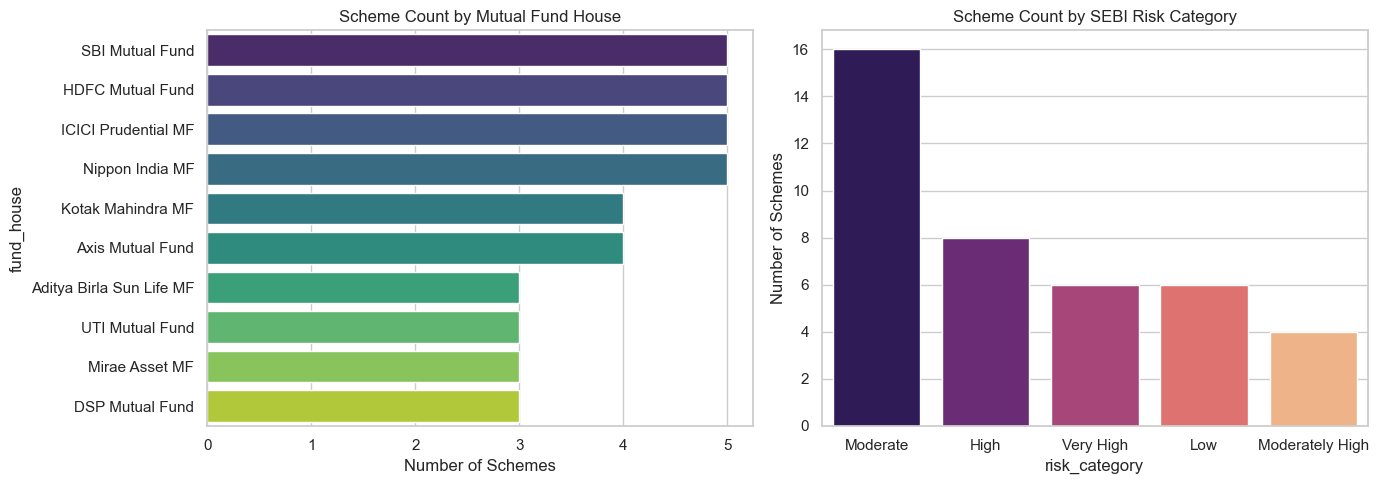

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(data=fm, y="fund_house", order=fm["fund_house"].value_counts().index, ax=axes[0], palette="viridis")
axes[0].set_title("Scheme Count by Mutual Fund House")
axes[0].set_xlabel("Number of Schemes")

sns.countplot(data=fm, x="risk_category", order=fm["risk_category"].value_counts().index, ax=axes[1], palette="magma")
axes[1].set_title("Scheme Count by SEBI Risk Category")
axes[1].set_ylabel("Number of Schemes")

plt.tight_layout()
plt.show()

### 4. AMFI Scheme Code Referential Integrity Validation
Confirming that every code in `fund_master` exists in `nav_history`.

In [5]:
fm_codes = set(dfs["fund_master"]["amfi_code"].unique())
nav_codes = set(dfs["nav_history"]["amfi_code"].unique())

missing_in_nav = fm_codes - nav_codes
print(f"Unique codes in fund_master:        {len(fm_codes)}")
print(f"Unique codes in nav_history:        {len(nav_codes)}")
print(f"Codes in fund_master missing in NAV: {len(missing_in_nav)}")

if not missing_in_nav:
    print("\n[✓ PASS] Referential Integrity Confirmed: 100% of fund_master schemes have NAV records.")
else:
    print(f"\n[X FAIL] Discrepancy detected: {missing_in_nav}")

Unique codes in fund_master:        40
Unique codes in nav_history:        40
Codes in fund_master missing in NAV: 0

[✓ PASS] Referential Integrity Confirmed: 100% of fund_master schemes have NAV records.


### 5. Live NAV Ingestion via mfapi.in REST API
Testing live ingestion for HDFC Top 100 Direct and 5 key mutual fund schemes.

In [6]:
url = "https://api.mfapi.in/mf/125497"
res = requests.get(url, timeout=15)
data = res.json()
meta = data.get("meta", {})
records = data.get("data", [])

print(f"Scheme Name: {meta.get('scheme_name')}")
print(f"Fund House:  {meta.get('fund_house')}")
print(f"Category:    {meta.get('scheme_category')}")
print(f"Total Historical NAV Dates: {len(records)}")
if records:
    print(f"Latest NAV on {records[0]['date']}: Rs. {records[0]['nav']}")
    print(f"Earliest NAV on {records[-1]['date']}: Rs. {records[-1]['nav']}")

Scheme Name: SBI SMALL CAP FUND - Direct Plan - Growth
Fund House:  SBI Mutual Fund
Category:    Equity Scheme - Small Cap Fund
Total Historical NAV Dates: 3209
Latest NAV on 18-11-2026: Rs. 208.93220
Earliest NAV on 18-11-2013: Rs. 13.08940
